# Четыре стакана компота
## Q-learning и SARSA без отрицательных наград

Практическая работа №4 · «Интеллектуальные системы и технологии»

**Цель:** научить агента уравнивать объёмы в четырёх стаканах за минимальное
число поднятий. Из одного поднятого стакана можно налить сразу в несколько других.

Ноутбук содержит математическую модель, описание алгоритмов, реализацию
обоих методов в соседнем модуле, эксперимент и проверку результата.
Запуск: **Run → Run All Cells**. В JupyterLite всё обучение выполняется в браузере;
первый запуск загружает Python и библиотеки из сети.

Для полного опыта используйте `MODE = "full"`; для быстрого — `"quick"`.
Режим `"saved"` открывает измеренный полный результат без нового обучения.
Уже выполненные ячейки позволяют прочитать работу без запуска.

## 1. Математическая модель и состояния

Принимаем допущения: одинаковые стаканы, без потерь, без внешней воды;
вместимость каждого $C=6$, общий объём $V=12$, объёмы целочисленные.
Эти числа **выбраны для модели** и являются её допущениями.
Например, единица может соответствовать 50 мл.

$$s=(v_0,v_1,v_2,v_3),\quad v_i\in\{0,\ldots,6\},\quad \sum_i v_i=12.$$

Четыре переменные, из которых три независимы. Стаканы различимы.
Целевое состояние $(3,3,3,3)$.

$$|S|=[x^{12}](1+x+\ldots+x^6)^4
=\binom{15}{3}-4\binom{8}{3}=231.$$

230 неготовых стартовых состояний и одно целевое. При непрерывных объёмах
состояний было бы бесконечно много. Сумма объёмов должна делиться на четыре,
иначе точное равенство в выбранной целочисленной сетке недостижимо.

In [1]:
import sys
if sys.platform == "emscripten":
    import piplite
    await piplite.install(["numpy", "matplotlib"])

import json
import inspect
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from kompot_rl import Config, GlassEnv, shortest_distances, train, evaluate, rollout
from experiment import (run_experiment, summary_rows, plot_results,
                        policy_q, plot_trajectory)

env = GlassEnv()
print(f"Состояний: {len(env.states)}; стартов: {len(env.starts)}")
print(f"Кодов действий: {env.n_actions}; допустимых пар: {sum(map(len, env.actions))}")
print("Цель:", env.goal)
assert len(env.states) == 231

Состояний: 231; стартов: 230
Кодов действий: 1368; допустимых пар: 17816
Цель: (3, 3, 3, 3)


## 2. Действия и кодирование

Один шаг — **одно полное поднятие и разлив**. Выбираем источник $i$ и
объёмы $(q_1,q_2,q_3)$ для остальных стаканов в порядке их номеров.

$$k=49q_1+7q_2+q_3,\quad a=342i+k-1.$$

$i\in\{0,1,2,3\}$, $q_j\in\{0,\ldots,6\}$, $k>0$.
Код действия — целое число от 0 до 1367.
В конкретном нетерминальном состоянии допустимы только 54–86 кодов:
нельзя перелить больше содержимого источника или переполнить получателя.
Маска задаёт ограничения физики; в ней остаются ходы, удаляющие от цели.

Пример: из $(6,2,2,2)$ поднять первый стакан и налить по единице в остальные.
Это действие с кодом 56, результат $(3,3,3,3)$, **одно** поднятие.
Какой стакан сейчас в руке, хранить не нужно: действие завершается до следующего состояния.

In [2]:
env.reset((6, 2, 2, 2))
a = env.encode_action(0, (1, 1, 1))
print("Код:", a, "—", env.describe(a))
state, reward, terminated, truncated, info = env.step(a)
print("Результат:", state, "награда:", reward, "поднятий:", info["lifts"])
assert a == 56 and terminated and reward == 1 and info["lifts"] == 1

Код: 56 — Поднять стакан 1; в стакан 2: 1, в стакан 3: 1, в стакан 4: 1
Результат: (3, 3, 3, 3) награда: 1.0 поднятий: 1


## 3. Награда, штрафы и окончание эпизода

$$r(s,a,s')=\begin{cases}1,&s'=(3,3,3,3),\\0,&\text{иначе.}\end{cases}$$

**Отрицательных наград нет.** За промежуточное «правильное» поднятие — 0,
за достижение цели — +1.

Чтобы предпочитать меньше поднятий, максимизируем дисконтированный доход:

$$G_0=\sum_{t=0}^{L-1}\gamma^t r_{t+1}=\gamma^{L-1},\quad\gamma=0.9.$$

Успех за одно поднятие даёт 1, за два — 0.9, за три — 0.81.
Просто недисконтированная сумма наград равна 1 при любом успехе и не различала бы длину пути.

**Окончание:** равенство объёмов (`terminated=True`).
30 поднятий — технический предел попытки (`truncated=True`), а не достижение цели.
Отдельного штрафа за прерывание нет. В обновлениях после прерывания сохраняется
bootstrap; после настоящего завершения он равен нулю. Поэтому технический
счётчик не меняет марковское состояние из четырёх объёмов.

In [3]:
for lifts in (1, 2, 3, 10):
    print(f"{lifts:2} поднятий: G₀ = {env.config.gamma**(lifts-1):.5f}")

 1 поднятий: G₀ = 1.00000
 2 поднятий: G₀ = 0.90000
 3 поднятий: G₀ = 0.81000
10 поднятий: G₀ = 0.38742


## 4. Два метода обучения

**Q-learning (off-policy):**
$$Q(s,a)\leftarrow Q(s,a)+\alpha[r+\gamma\max_b Q(s',b)-Q(s,a)].$$

**SARSA (on-policy):**
$$Q(s,a)\leftarrow Q(s,a)+\alpha[r+\gamma Q(s',a')-Q(s,a)],$$
где $a'$ действительно выбрано ε-жадной стратегией.

Общие параметры: $\alpha=0.5$, $\gamma=0.9$, начальная ε=0.6, конечная ε=0.05.
ε линейно уменьшается за первые 80% обучения, затем постоянна.
Q-таблицы изначально нулевые. При обучении равные максимумы выбираются случайно;
при проверке — первый допустимый код, чтобы оценка была воспроизводимой.

Ни один метод не получает правильные действия или число необходимых поднятий.
Ниже — фактически выполняемый общий цикл; различается формирование целевого значения.

In [4]:
print(inspect.getsource(train))

def train(env, method="q_learning", seed=0, progress=None):
    if method not in ("q_learning", "sarsa"):
        raise ValueError("method must be q_learning or sarsa")
    cfg = env.config
    q = new_q(env)
    # Equal starting states for paired seeds; exploration gets its own RNG.
    starts = np.random.default_rng(seed).choice(env.starts, size=cfg.episodes)
    rng = np.random.default_rng(seed+100_000)
    distances = shortest_distances(env)
    history = {"return": [], "raw_reward": [], "lifts": [], "epsilon": [], "checkpoints": []}
    history["checkpoints"].append({"episode": 0, **evaluate(env, q, distances)})
    started = perf_counter()
    for episode, start in enumerate(starts):
        fraction = min(episode/max(1, int(cfg.episodes*0.8)-1), 1.0)
        epsilon = cfg.epsilon_start + fraction*(cfg.epsilon_end-cfg.epsilon_start)
        sid = int(start)
        action = epsilon_greedy(q[sid], epsilon, rng)
        solved = False
        for step in range(cfg.max_steps):
     

## 5. Независимый точный минимум

Для каждого состояния строим все физически допустимые переходы и считаем
кратчайшее расстояние до цели обратным BFS. Этот алгоритм используется **только
для оценки**, не для обучения.

Есть и доказательство: каждый стакан выше среднего обязательно нужно поднять,
иначе его объём не уменьшится. Достаточно поднять каждый такой стакан один раз
и разлить его избыток по дефицитам. Значит, минимум равен числу стаканов выше среднего.
Во всех 231 состояниях проверяем совпадение этого результата с BFS.

In [5]:
distances = shortest_distances(env)
lower_bound = np.array([sum(v > env.target for v in s) for s in env.states])
np.testing.assert_array_equal(distances, lower_bound)
values, counts = np.unique(distances[env.starts], return_counts=True)
print("Минимальное число поднятий → количество стартов:")
for value, count in zip(values, counts):
    print(f"{value} → {count}")
print(f"Средний точный минимум: {distances[env.starts].mean():.6f}")

Минимальное число поднятий → количество стартов:
1 → 76
2 → 150
3 → 4
Средний точный минимум: 1.686957


## 6. Эксперимент

Полный режим: 200 000 эпизодов × 5 seed × 2 метода. Проверка каждые 5000 эпизодов.
У парных seed одинаковая последовательность стартов; генераторы стартов и разведки разделены.
Начальные состояния выбираются равномерно из 230 нецелевых вариантов.

Каждая проверка — жадная стратегия на **всех 230** стартах без обучения.
Это проверка освоения конечной среды, **не** обобщение на невиденные объёмы.
Сравниваем успех, оптимальность, число поднятий и дисконтированный доход.
Неуспех учитывается как 30 поднятий, а не удаляется из среднего.

Сохранённый полный эксперимент доступен независимо от выбранного режима.
Быстрый режим имеет меньший бюджет, поэтому его результаты могут отличаться.

In [6]:
MODE = "full"  # "full", "quick" или "saved"

saved = json.loads(Path("reference/results.json").read_text(encoding="utf-8"))
if MODE == "full":
    result = run_experiment(Config(), seeds=(0, 1, 2, 3, 4))
elif MODE == "quick":
    result = run_experiment(Config(episodes=40000, eval_every=1000), seeds=(0, 1, 2))
elif MODE == "saved":
    result = saved
else:
    raise ValueError("Выберите full, quick или saved")
print(f"Готово: {MODE}; {result['config']['episodes']} эпизодов на запуск")

Q-learning, seed=0: success=100.0%, optimal=100.0%, lifts=1.687


Q-learning, seed=1: success=100.0%, optimal=98.7%, lifts=1.700


Q-learning, seed=2: success=100.0%, optimal=100.0%, lifts=1.687


Q-learning, seed=3: success=100.0%, optimal=99.1%, lifts=1.696


Q-learning, seed=4: success=100.0%, optimal=99.1%, lifts=1.696


SARSA, seed=0: success=100.0%, optimal=93.9%, lifts=1.752


SARSA, seed=1: success=100.0%, optimal=95.2%, lifts=1.735


SARSA, seed=2: success=100.0%, optimal=94.3%, lifts=1.743


SARSA, seed=3: success=100.0%, optimal=96.5%, lifts=1.722


SARSA, seed=4: success=100.0%, optimal=93.5%, lifts=1.752


Готово: full; 200000 эпизодов на запуск


## 7. Кривые обучения и сравнение

Сверху — средние по последовательным блокам эпизодов: дисконтированный доход
и исходная сумма наград (0 или 1). Снизу — проверка жадных стратегий.
Линии показывают среднее по seed, полоса — ± одно выборочное стандартное отклонение,
**не** доверительный интервал. Разведка во время обучения может снижать доход
даже тогда, когда жадная стратегия уже хорошая.

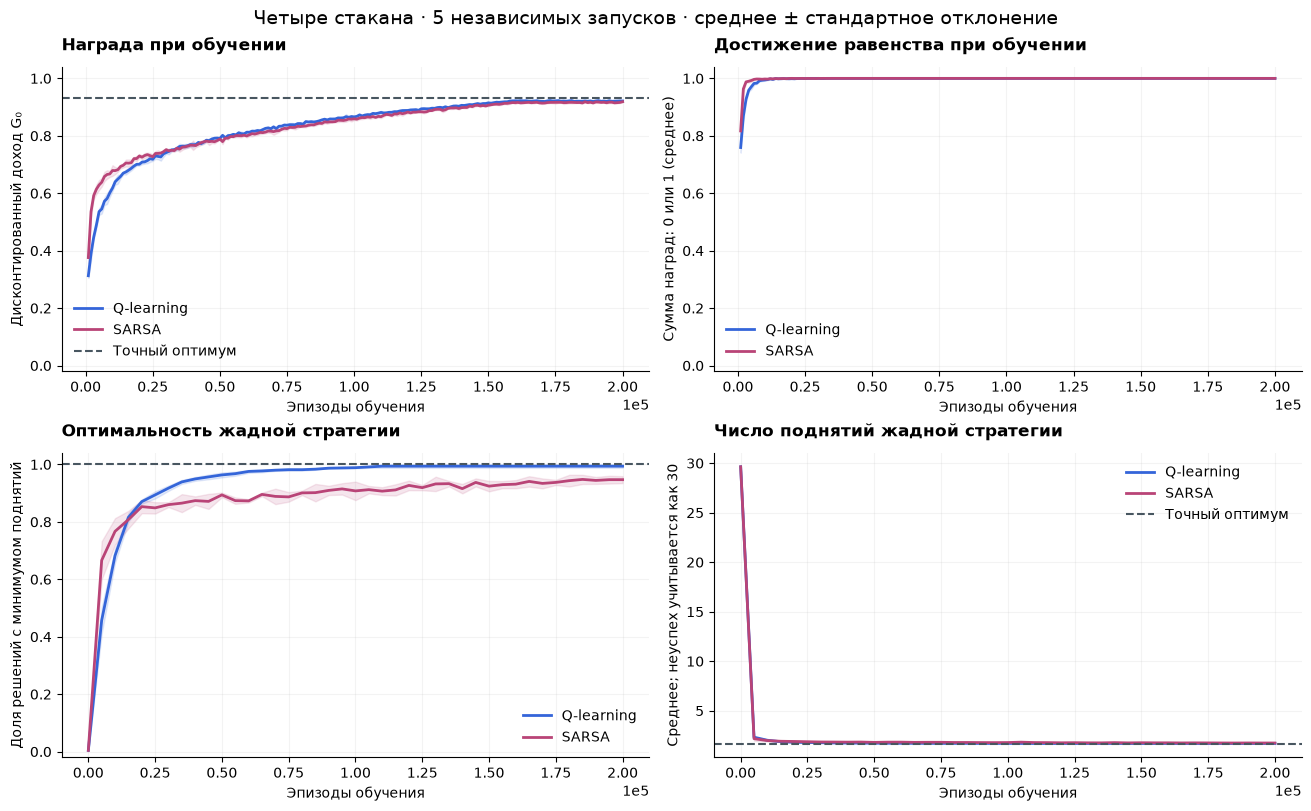

| Метод | Успех | Оптимум | Поднятия | Доход | AUC дохода |
|---|---:|---:|---:|---:|---:|
| Q-learning | 100.0% | 99.39% ± 0.58 п.п. | 1.693 ± 0.006 | 0.9309 | 0.9152 |
| SARSA | 100.0% | 94.70% ± 1.21 п.п. | 1.741 ± 0.013 | 0.9266 | 0.9096 |
| Случайный выбор | 12.0% | 0.83% | 28.264 | 0.0392 | — |
| Точный оптимум | 100.0% | 100.00% | 1.687 | 0.9315 | — |

In [7]:
fig = plot_results(result)
plt.show()

def results_table(data):
    lines = ["| Метод | Успех | Оптимум | Поднятия | Доход | AUC дохода |",
             "|---|---:|---:|---:|---:|---:|"]
    for row in summary_rows(data):
        lines.append(f"| {row['method']} | {row['success_rate']:.1%} | "
                     f"{row['optimal_rate']:.2%} ± {100*row['optimal_rate_std']:.2f} п.п. | "
                     f"{row['mean_lifts_capped']:.3f} ± {row['mean_lifts_capped_std']:.3f} | "
                     f"{row['discounted_return']:.4f} | {row['auc_return']:.4f} |")
    for key, label in (("random", "Случайный выбор"), ("oracle", "Точный оптимум")):
        row = data[key]
        lines.append(f"| {label} | {row['success_rate']:.1%} | {row['optimal_rate']:.2%} | "
                     f"{row['mean_lifts_capped']:.3f} | {row['discounted_return']:.4f} | — |")
    display(Markdown("\n".join(lines)))

results_table(result)
if MODE != "full":
    display(Markdown("### Для сравнения: сохранённый полный эксперимент (200 000 × 5)"))
    results_table(saved)

## 8. Демонстрация обученной стратегии

Используем заранее выбранный **seed=0**, а не выбираем лучший результат после опыта.
Измените `START` и повторите ячейку: допустимы целые объёмы 0–6 с суммой 12.
График показывает каждый завершённый акт поднятия. Пунктир — целевой объём.

Старт: (4, 4, 4, 0) Метод: q_learning
1. Поднять стакан 3; в стакан 1: 1, в стакан 2: 2; (5, 6, 1, 0); r=0
2. Поднять стакан 2; в стакан 3: 2, в стакан 4: 2; (5, 2, 3, 2); r=0
3. Поднять стакан 1; в стакан 2: 1, в стакан 4: 1; (3, 3, 3, 3); r=1
Успех: True; поднятий: 3; точный минимум: 3


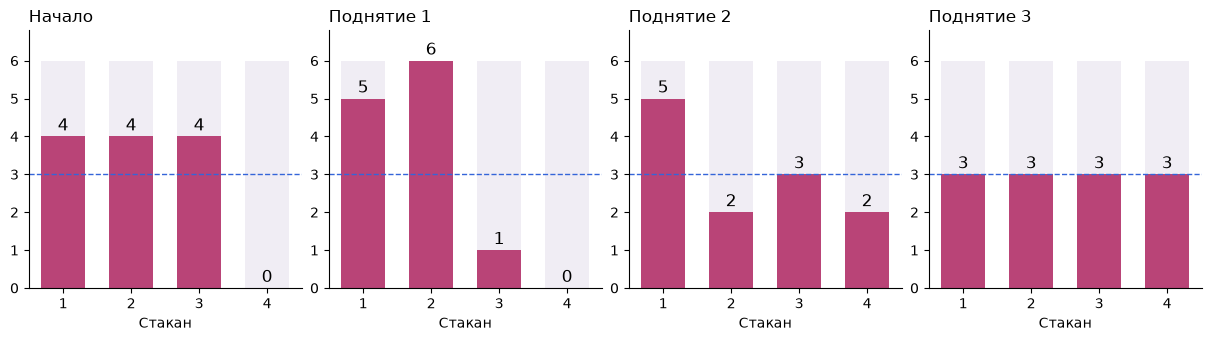

In [8]:
START = (4, 4, 4, 0)
METHOD = "q_learning"  # или "sarsa"

demo_env = GlassEnv(Config(**result["config"]))
demo_q = policy_q(demo_env, result["policies"][METHOD])
path, solved = rollout(demo_env, demo_q, START)
print("Старт:", START, "Метод:", METHOD)
for i, step in enumerate(path, 1):
    print(f"{i}. {demo_env.describe(step['action'])}; {step['after']}; r={step['reward']:.0f}")
optimal = int(shortest_distances(demo_env)[demo_env.state_index[START]])
print(f"Успех: {solved}; поднятий: {len(path)}; точный минимум: {optimal}")
if len(path) <= 6:
    plot_trajectory(demo_env, path, START)
    plt.show()
else:
    print("Траектория длиннее 6 шагов; см. текстовый список выше.")

## 9. Выводы и ограничения

В сохранённом полном опыте оба метода достигают равенства во всех состояниях.
Q-learning: **99.39% ± 0.58 п.п.** оптимальных решений;
SARSA: **94.70% ± 1.21 п.п.**. Среднее число поднятий — 1.693 и 1.741
при точном минимуме 1.687. Демонстрационный Q-learning с seed=0 оптимален во всех 230 стартах.

При выбранном бюджете и общих параметрах Q-learning лучше по итоговой
оптимальности и среднему доходу. Возможное объяснение — SARSA учитывает
разведочные действия в целевом значении, а ε остаётся положительной.
Это интерпретация результата, а не доказательство универсального превосходства.
Раннее обучение у SARSA на части интервала проходит быстрее — это видно на кривых.

Не утверждаем сходимость после фиксированного числа эпизодов: α постоянная,
ε не исчезает, оптимальность не равна 100% во всех запусках.
Полосы показывают только разброс между пятью seed. Параметры выбраны после
пробных прогонов без отдельного поиска оптимальных настроек каждого метода.

Дискретизация ограничивает точность объёмов. При других вместимостях и общем
объёме меняются множества состояний и действий; табличное обучение нужно повторить.

### Источники

- «ИСиТ пр.pptx», задание №4: условие, два метода, кривые обучения и сравнение.
- «ИСиТ RL small.pdf»: MDP, дисконтирование, SARSA и Q-обучение.
- Sutton & Barto, [Reinforcement Learning, 2nd edition](http://incompleteideas.net/book/the-book-2nd.html), главы 3 и 6.
- [Официальное развёртывание JupyterLite на GitHub Pages](https://jupyterlite.readthedocs.io/en/stable/quickstart/deploy.html).

Исходные лекционные файлы в репозиторий не включены.